## 混淆矩阵

# 混淆矩阵（二分类，0负 / 1正）
二分类预测一共就4种情况，对应混淆矩阵4个单元格：

|符号|全称|中文含义|通俗解释|
| ---- | ---- | ---- | ---- |
|TP|True Positive|真正例|真实是1（正），预测为1（正） ✅|
|FN|False Negative|假负例|真实是1（正），预测为0（负） ❌ 漏检|
|FP|False Positive|假正例|真实是0（负），预测为1（正） ❌ 误报|
|TN|True Negative|真负例|真实是0（负），预测为0（负） ✅|

> 记忆口诀（很适合做题）：
> **第一个单词 True/False：预测结果对不对；第二个 Positive/Negative：模型预测出来是什么类别。**
> - True：预测正确
> - False：预测错误
> - Positive：模型输出正类(1)
> - Negative：模型输出负类(0)

举例子：疾病检测（患病=正1，健康=负0）
- TP：真得病，模型判断得病
- FN：真得病，模型判断健康（漏诊）
- FP：没病，模型判断得病（误诊）
- TN：没病，模型判断健康

## 二分类混淆矩阵表格写法（考试标准）
|真实\预测|预测为正（1）|预测为负（0）|
|---|---|---|
|真实为正（1）|TP|FN|
|真实为负（0）|FP|TN|

## 衍生指标（紧接着混淆矩阵必考，朴素贝叶斯评估也用）
1. **准确率 Accuracy**
$$Acc=\frac{TP+TN}{TP+TN+FP+FN}$$
全部样本预测正确的比例。
> 缺点：样本不均衡时不准（比如99%都是负样本，无脑猜负就能99%准确率）

2. **精确率 Precision（查准率）**
$$P=\frac{TP}{TP+FP}$$
**模型预测为正的样本里，真正是正的比例**。
> 垃圾邮件场景：预测是垃圾邮件的样本中，确实是垃圾邮件多少。

3. **召回率 Recall（查全率）**
$$R=\frac{TP}{TP+FN}$$
**真实所有正样本中，被模型找出来的比例**。
> 疾病诊断：所有病人里，被检测出来的病人占比。

4. **F1分数**
$$F_1=\frac{2\cdot P\cdot R}{P+R}$$
精确率和召回率的调和平均，综合衡量模型。

> 考点区分：
> - 精确率：预测出来的正样本靠谱吗？
> - 召回率：真实的正样本抓全了吗？

In [1]:
#作图包，对于matplotlib的封装，提供更高级的接口，绘制出更美观的图表
# pip install seaborn 

In [2]:
#导入库
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
#模型的评估方法，metrics主要用于评估模型的性能
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
#需要下载seaborn

import seaborn as sns

In [73]:
## 1. 加载数据集
iris = datasets.load_iris()
knc = KNeighborsClassifier(n_neighbors=3)

In [74]:
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.3, random_state=42)

In [75]:
knc.fit(X_train, y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [76]:
y_pred = knc.predict(X_test)
knc.score(X_test, y_test)

1.0

In [77]:
#准确率
accuracy_score(y_test, y_pred)

1.0

In [78]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[19,  0,  0],
       [ 0, 13,  0],
       [ 0,  0, 13]], dtype=int64)

<Figure size 800x600 with 0 Axes>

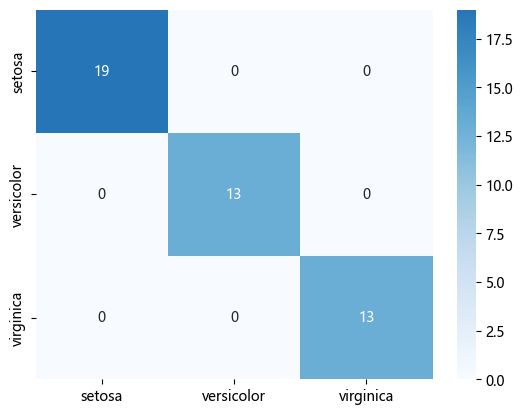

<Figure size 800x600 with 0 Axes>

In [79]:
#seaborn绘制混淆矩阵
#annot=True表示在每个单元格中显示数字，
#fmt='d'表示以整数形式显示注释，cmap='Blues'表示使用蓝色调的颜色映射，xticklabels和yticklabels分别设置x轴和y轴的标签为鸢尾花的类别名称。
#center=13表示将颜色映射的中心值设置为13，这样可以更好地显示混淆矩阵中的差异。
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names,center = 13,yticklabels=iris.target_names)
plt.figure(figsize=(8, 6))

In [80]:
from sklearn.metrics import ConfusionMatrixDisplay


In [81]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

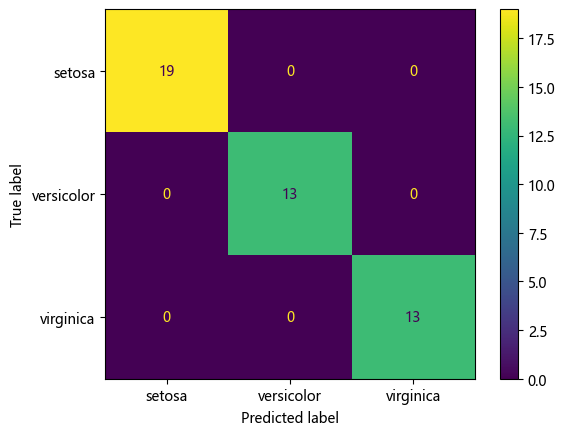

In [83]:
ConfusionMatrixDisplay(cm,display_labels=iris.target_names).plot()

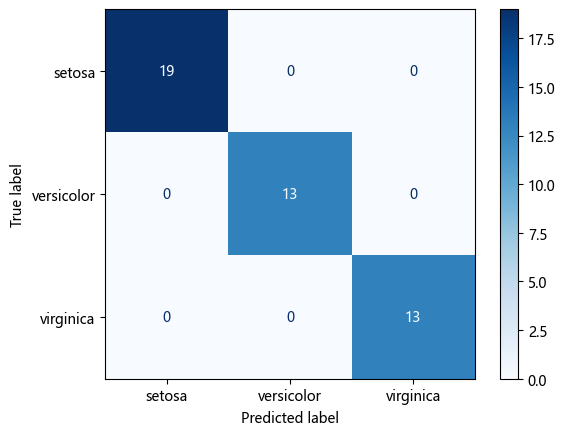

In [84]:
ConfusionMatrixDisplay.from_estimator(knc, X_test, y_test, display_labels=iris.target_names, cmap=plt.cm.Blues)